# Diabetes readmission: proposed cleaning vs. the alternatives

NOVA IMS Enterprise Data Science Bootcamp, 2026-27. Davide Corbo.

The README (Step 1) lists the cleaning decisions that the team still has to agree
on, each with a proposal and an alternative. `02_model_exploration.ipynb` implements
only the proposals. Here I test every alternative against them, one at a time and all
together, with the same models and the same patient-grouped folds, so the team can
decide with numbers.

| ID | Decision | Proposal (variant P) | Alternative tested |
|---|---|---|---|
| D-004 | Expired encounters | Remove | none: the outcome cannot be observed |
| D-005 | Hospice encounters | Remove (771 rows) | **A1**: keep them with a `hospice` flag |
| D-007 | Rare medications | Drop the 10 drugs with < 100 non-"No" rows | **A2**: also keep one `other_meds` feature |
| D-009 | `medical_specialty` | Top-10 levels + rest grouped, in the pipeline | **A3**: fixed grouping by clinical area |
| D-006 | `weight` | Drop | **A4**: keep a `weight_recorded` flag (from the decision log) |
| D-010 | Rows used to train | All encounters, grouped on `patient_nbr` | **A5**: first encounter per patient (Strack et al.) |
| | | | **A1–A4**: the four feature alternatives together |

All the options are implemented in `clean` (`src/features.py`), whose defaults are
the proposals, and in `first_encounter_only`.

## How the comparison is kept fair, and free of leakage

1. **The test patients are excluded from the whole experiment.** They are the test
   set of `split_by_patient` (seed 42), the one used for the final score. Choosing
   the cleaning is a modelling choice: if I looked at the test patients here, the
   final test score would no longer be a test opened once.
2. **One fold per patient, the same in every variant.** The remaining (development)
   patients get a fold number from 0 to 4 once, before any variant is built. Every
   variant and model is then scored on exactly the same patients in each fold, so the
   comparison is paired, fold by fold. A patient is never in the fitting and the
   scored part of the same fold (checked with `assert`).
3. **The same evaluation rows for everyone.** A1 adds the hospice rows and A5 removes
   the later encounters, so their "own" scores would be measured on different
   populations. The main score is therefore always computed on the rows of the
   proposal P (every non-death, non-hospice encounter): the use case of D-010, where
   the hospital scores every discharge. A5 is also scored on the first encounters
   only, the population of Strack et al.
4. **Everything that learns is inside the pipeline** (rare levels, scaling,
   encoding), refitted in every fold. The options of `clean` are fixed row-by-row
   rules; `first_encounter_only` only looks at rows of the same patient, who is never
   split across folds.
5. **Two models**: a logistic regression (L2) and a histogram gradient boosting with
   fixed, conservative hyperparameters (no tuning here, so that the comparison is
   about the data, not the models). A cleaning choice that helps only one of them is
   weaker evidence than one that helps both.

Decision rule: an alternative "wins" only if it beats P
in at least 4 of the 5 folds; otherwise it is a tie and the decision is taken on
other grounds (simplicity, meaning, the project brief).

----------------------------------------------------------------------
# STAGE 0. GET READY
----------------------------------------------------------------------

In [1]:
import sys
from pathlib import Path

PROJECT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src" / "data_prep.py").exists()
)
sys.path.insert(0, str(PROJECT / "src"))

print("Project folder :", PROJECT)
print("Python 3.13    :", sys.version_info[:2] == (3, 13))
print("Running .venv  :", ".venv" in sys.executable)
print("Data in place  :", (PROJECT / "data" / "diabetic_data.csv").exists())

Project folder : C:\Users\david\Documents\DiabetesProject\Diabetes-Hospital-Readmission-Data-Science-Project
Python 3.13    : True
Running .venv  : True
Data in place  : True


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

from data_prep import add_mapping_descriptions, load_mappings, load_raw
from evaluation import LABELS, scores
from features import (
    GROUP,
    HOSPICE,
    TARGET,
    clean,
    feature_lists,
    first_encounter_only,
    split_by_patient,
)
from preprocessing import make_pipeline

SEED = 42
N_FOLDS = 5
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

----------------------------------------------------------------------
# STAGE 1. THE CLEANED VARIANTS
----------------------------------------------------------------------
**1.1** Each variant is a set of options for `clean` (and `first_only` for A5, which
changes the training rows only). The table shows what each one does to the data.

In [3]:
raw = add_mapping_descriptions(load_raw(), load_mappings())

ALTERNATIVES = {
    "A1: hospice kept + flag": {"hospice": "flag"},
    "A2: other_meds feature": {"rare_meds": "group"},
    "A3: specialty by clinical area": {"specialty": "clinical"},
    "A4: weight_recorded flag": {"weight_flag": True},
    "A5: first encounter only": {"first_only": True},
}
VARIANTS = {"P: proposals": {}} | ALTERNATIVES
VARIANTS["A1-A4 together"] = {
    k: v for opts in list(ALTERNATIVES.values())[:4] for k, v in opts.items()
}


def build(options):
    """The cleaned table and the training pool of one variant."""
    options = dict(options)
    first_only = options.pop("first_only", False)
    data = clean(raw, **options)
    pool = first_encounter_only(data) if first_only else data
    return data, pool, options


overview = []
for name, options in VARIANTS.items():
    data, pool, _ = build(options)
    numeric, categorical = feature_lists(data)
    overview.append(
        {
            "variant": name,
            "training_rows": len(pool),
            "patients": pool[GROUP].nunique(),
            "readmitted_30_rate": pool[TARGET].mean(),
            "numeric": len(numeric),
            "categorical": len(categorical),
            "specialty_levels": data["medical_specialty"].nunique(),
        }
    )
pd.DataFrame(overview).set_index("variant").round(4)

,training_rows,patients,readmitted_30_rate,numeric,categorical,specialty_levels
variant,,,,,,
P: proposals,99343,69990,0.1139,12,25,73
A1: hospice kept + flag,100114,70439,0.1134,13,25,73
A2: other_meds feature,99343,69990,0.1139,12,26,73
A3: specialty by clinical area,99343,69990,0.1139,12,25,15
A4: weight_recorded flag,99343,69990,0.1139,13,25,73
A5: first encounter only,69990,69990,0.0898,12,25,73
A1-A4 together,100114,70439,0.1134,14,26,15


----------------------------------------------------------------------
# STAGE 2. PATIENTS, FOLDS AND EVALUATION ROWS
----------------------------------------------------------------------
**2.1** The test patients of `split_by_patient` (seed 42) are removed. The other
patients get one fold each, at random, once. The patients who appear only in
A1 (all their encounters are hospice) are development patients too.

In [4]:
base = clean(raw)
_, _, test = split_by_patient(base, seed=SEED)
TEST_PATIENTS = set(test[GROUP])

dev_patients = np.array(sorted(set(raw[GROUP]) - TEST_PATIENTS))
rng = np.random.default_rng(SEED)
FOLD = pd.Series(
    np.arange(len(dev_patients)) % N_FOLDS, index=rng.permutation(dev_patients)
)

# The evaluation rows: P's development encounters, with two flags
dev_base = base[~base[GROUP].isin(TEST_PATIENTS)]
EVAL_IDS = set(dev_base["encounter_id"])
FIRST_IDS = set(first_encounter_only(dev_base)["encounter_id"])

per_fold = dev_base.assign(fold=dev_base[GROUP].map(FOLD)).groupby("fold")
pd.DataFrame(
    {
        "patients": per_fold[GROUP].nunique(),
        "encounters": per_fold.size(),
        "readmitted_30_rate": per_fold[TARGET].mean(),
    }
).round(3)

,patients,encounters,readmitted_30_rate
fold,,,
0,11200,16061,0.116
1,11189,15914,0.119
2,11193,15924,0.113
3,11228,15825,0.113
4,11182,15817,0.111


The five folds have about the same size and the same `<30` rate, so no fold is much
easier than the others by construction.

----------------------------------------------------------------------
# STAGE 3. THE EXPERIMENT
----------------------------------------------------------------------
**3.1** For every variant, model and fold: fit the pipeline on the training pool of
the other four folds, score every development encounter of the variant in the held-out
fold, and keep the predictions. Metrics come in Stage 4, on the agreed evaluation
rows. (7 variants × 2 models × 5 folds = 70 fits; a few minutes.)

In [5]:
MODELS = {
    "Logistic regression": (
        "linear",
        lambda categorical: LogisticRegression(
            C=1.0, class_weight="balanced", max_iter=2000
        ),
    ),
    "Gradient boosting": (
        "ordinal",
        lambda categorical: HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=150,
            max_leaf_nodes=15,
            min_samples_leaf=200,
            l2_regularization=1.0,
            categorical_features=categorical,
            class_weight="balanced",
            early_stopping=False,
            random_state=SEED,
        ),
    ),
}

predictions = []
for vname, options in VARIANTS.items():
    data, pool, clean_options = build(options)
    data = data[~data[GROUP].isin(TEST_PATIENTS)]
    pool = pool[~pool[GROUP].isin(TEST_PATIENTS)]
    numeric, categorical = feature_lists(data)
    features = numeric + categorical
    # A3 has already grouped the specialty by hand: keep all its areas
    no_top_n = (
        ("medical_specialty",) if clean_options.get("specialty") == "clinical" else ()
    )
    for mname, (kind, make_model) in MODELS.items():
        pipe = make_pipeline(
            kind,
            make_model(categorical),
            numeric=numeric,
            categorical=categorical,
            no_top_n=no_top_n,
        )
        for k in range(N_FOLDS):
            fit_rows = pool[pool[GROUP].map(FOLD) != k]
            score_rows = data[data[GROUP].map(FOLD) == k]
            assert not set(fit_rows[GROUP]) & set(score_rows[GROUP])
            model = clone(pipe).fit(fit_rows[features], fit_rows[TARGET])
            predictions.append(
                pd.DataFrame(
                    {
                        "variant": vname,
                        "model": mname,
                        "fold": k,
                        "encounter_id": score_rows["encounter_id"].to_numpy(),
                        "y": score_rows[TARGET].to_numpy(),
                        "p": model.predict_proba(score_rows[features])[:, 1],
                    }
                )
            )
    print(f"done: {vname}")

predictions = pd.concat(predictions, ignore_index=True)
predictions["evaluation_row"] = predictions["encounter_id"].isin(EVAL_IDS)
predictions["first_encounter"] = predictions["encounter_id"].isin(FIRST_IDS)

done: P: proposals


done: A1: hospice kept + flag


done: A2: other_meds feature


done: A3: specialty by clinical area


done: A4: weight_recorded flag


done: A5: first encounter only


done: A1-A4 together


----------------------------------------------------------------------
# STAGE 4. RESULTS
----------------------------------------------------------------------
**4.1** The metrics of each variant, model and fold on two populations:

- `all encounters`: the evaluation rows of P (every discharge is scored, D-010 A).
- `first encounters`: only the first encounter of each patient (D-010 B).

One table per population: the mean over the 5 folds of PR-AUC (the main metric),
ROC-AUC and top-10% recall, for each model. Darker = better, within each column.

In [6]:
METRICS = ["pr_auc", "roc_auc", "recall_top10"]
POPULATIONS = {
    "all encounters": "evaluation_row",
    "first encounters": "evaluation_row & first_encounter",
}

rows = []
for population, condition in POPULATIONS.items():
    subset = predictions.query(condition)
    for (vname, mname, k), part in subset.groupby(
        ["variant", "model", "fold"], sort=False
    ):
        s = scores(part["y"], part["p"].to_numpy())
        rows.append(
            {"population": population, "variant": vname, "model": mname, "fold": k}
            | {m: s[m] for m in METRICS}
        )
by_fold = pd.DataFrame(rows)

summary = by_fold.pivot_table(
    index=["population", "variant"],
    columns="model",
    values=METRICS,
    aggfunc="mean",
    sort=False,
)
for population in POPULATIONS:
    display(
        summary.loc[population]
        .rename(columns=LABELS, level=0)
        .rename_axis(index=None, columns=[None, None])
        .style.format("{:.4f}")
        .background_gradient(cmap="Blues")
        .set_caption(f"Mean over 5 folds, scored on {population}")
    )

**4.2 Paired comparison with P.** For each alternative, model and population: the
mean difference with P over the 5 folds (positive = the alternative is better) and the
number of folds where it beats P and where it loses to P (identical predictions count
as neither). Following the decision rule, an alternative is `better` (green) only if
it wins at least 4 folds of 5, `worse` (red) if it loses at least 4, otherwise a `tie`.
The last column says whether the mean difference is large enough to matter (at least
0.005 PR-AUC, the grey band of the chart below). One table per population.

In [7]:
reference = by_fold[by_fold["variant"] == "P: proposals"].drop(columns="variant")
paired = by_fold[by_fold["variant"] != "P: proposals"].merge(
    reference, on=["population", "model", "fold"], suffixes=("", "_P")
)
for m in METRICS:
    paired[f"{m}_diff"] = paired[m] - paired[f"{m}_P"]

comparison = paired.groupby(["population", "variant", "model"], sort=False).agg(
    pr_auc_diff=("pr_auc_diff", "mean"),
    folds_won=("pr_auc_diff", lambda d: int((d > 0).sum())),
    folds_lost=("pr_auc_diff", lambda d: int((d < 0).sum())),
    roc_auc_diff=("roc_auc_diff", "mean"),
    recall_top10_diff=("recall_top10_diff", "mean"),
)
comparison["verdict"] = np.select(
    [comparison["folds_won"] >= 4, comparison["folds_lost"] >= 4],
    ["better", "worse"],
    default="tie",
)
comparison["matters"] = comparison["pr_auc_diff"].abs() >= 0.005

VERDICT_COLOURS = {
    "better": "background-color: #d4edda",
    "worse": "background-color: #f8d7da",
    "tie": "",
}
readable = comparison.rename(
    columns={
        "pr_auc_diff": "PR-AUC vs P",
        "folds_won": "Folds won",
        "folds_lost": "Folds lost",
        "roc_auc_diff": "ROC-AUC vs P",
        "recall_top10_diff": "Recall top 10% vs P",
        "verdict": "Verdict",
        "matters": "Matters (≥ 0.005)",
    }
)
for population in POPULATIONS:
    display(
        readable.loc[population]
        .rename_axis(index=[None, None])
        .style.format(
            "{:+.4f}", subset=["PR-AUC vs P", "ROC-AUC vs P", "Recall top 10% vs P"]
        )
        .map(VERDICT_COLOURS.get, subset=["Verdict"])
        .set_caption(f"Each alternative against P, scored on {population}")
    )

**4.3** The same comparison as a chart: the PR-AUC difference with P in each fold
(dots) and its mean (bar), on all encounters. The grey band is ±0.005: differences
inside it are too small to matter for the hospital.

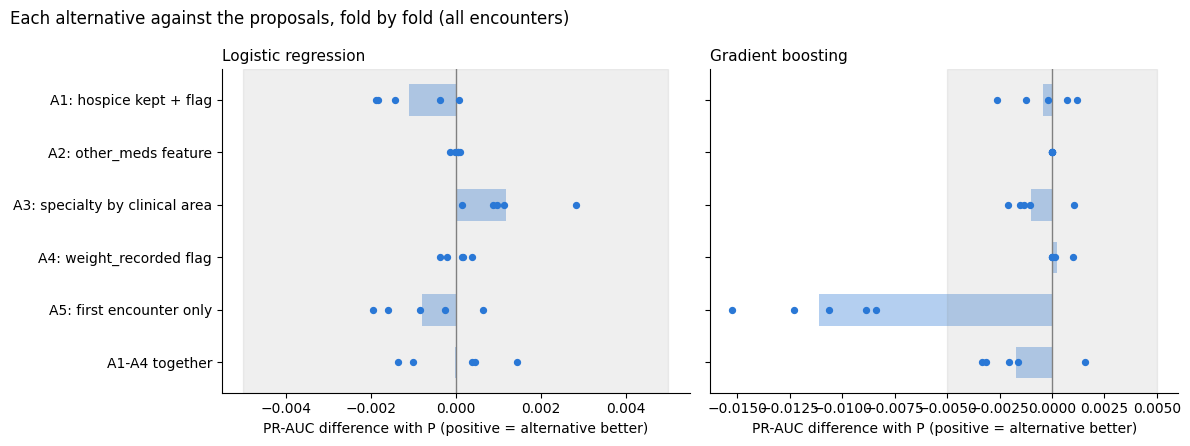

In [8]:
plot_data = paired[paired["population"] == "all encounters"]
variants = list(dict.fromkeys(plot_data["variant"]))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, mname in zip(axes, MODELS):
    part = plot_data[plot_data["model"] == mname]
    for i, vname in enumerate(variants):
        diffs = part.loc[part["variant"] == vname, "pr_auc_diff"]
        ax.barh(i, diffs.mean(), color="#2a78d6", alpha=0.35, height=0.6)
        ax.scatter(diffs, np.full(len(diffs), i), color="#2a78d6", s=18, zorder=3)
    ax.axvspan(-0.005, 0.005, color="gray", alpha=0.12)
    ax.axvline(0, color="gray", linewidth=1)
    ax.set_title(mname, loc="left", fontsize=11)
    ax.set_xlabel("PR-AUC difference with P (positive = alternative better)")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].set_yticks(range(len(variants)), variants)
fig.suptitle(
    "Each alternative against the proposals, fold by fold (all encounters)",
    x=0.01,
    ha="left",
    fontsize=12,
)
fig.tight_layout()
plt.show()

**4.4 The hospice patients themselves (A1).** If the hospice encounters are kept, the
hospital would also score them. How does A1 rank them, compared with the other
encounters? (Their `<30` rate is about 5.6%, half the average.)

In [9]:
hospice_ids = set(
    raw.loc[raw["discharge_disposition_id"].astype(int).isin(HOSPICE), "encounter_id"]
)
a1 = predictions[predictions["variant"].str.startswith("A1:")].copy()
a1["hospice"] = a1["encounter_id"].isin(hospice_ids)
a1.groupby(["model", "hospice"]).agg(
    encounters=("y", "size"),
    readmitted_30_rate=("y", "mean"),
    mean_score=("p", "mean"),
).round(3)

encounters  readmitted_30_rate  mean_score
model               hospice                                            
Gradient boosting   False         79541               0.114       0.457
                    True            695               0.056       0.322
Logistic regression False         79541               0.114       0.468
                    True            695               0.056       0.298

----------------------------------------------------------------------
# STAGE 5. CONCLUSIONS
----------------------------------------------------------------------
(Numbers from my run; with `SEED = 42` they come out the same every time.)

**The cleaning choices barely move the scores.** Apart from A5, every alternative
stays within ±0.002 PR-AUC of the proposals, far inside the ±0.005 band.
So for D-005, D-006, D-007 and D-009 the decision can be taken on meaning and
simplicity, not on performance.

| ID | Alternative | Result | Recommendation |
|---|---|---|---|
| D-010 | A5: train on the first encounter only | **Clearly worse** for gradient boosting: −0.011 PR-AUC on all encounters (0/5 folds won) and −0.005 even on first encounters, its own population. The later encounters are extra training data that helps. | **Accept the proposal (option A)**: all encounters, grouped split. |
| D-005 | A1: keep hospice + flag | Tie or slightly worse (−0.001). The models give hospice encounters lower scores (0.30–0.32 vs 0.46), consistent with their 5.6% `<30` rate. | **Accept the proposal (remove)**: no gain, and hospice is not a prevention target. |
| D-007 | A2: `other_meds` feature | No effect: the gradient boosting never uses it (identical predictions) and the logistic regression moves by 0.0000. Only 200-odd rows have a rare drug. | **Accept the proposal (drop)**: simpler. |
| D-006 | A4: `weight_recorded` flag | No effect (±0.0002). The `<30` rate is the same with and without a recorded weight (11.3% vs 11.3%). | **Accept the proposal (drop)**. |
| D-009 | A3: specialty by clinical area | Mixed and tiny: +0.001 for the logistic regression (5/5 folds), −0.001 for the gradient boosting (1/5 folds) on all encounters; +0.001 / +0.001 on first encounters. | **Tie.** Proposal by default; A3 is a defensible option if the final model is linear, because its groups are readable and keep Oncology/Hematology (about 20% `<30`), which the top-10 rule merges into the infrequent level. |
| — | A1–A4 together | Tie for the logistic regression, −0.002 for the gradient boosting. | Nothing to gain by combining them. |

**One caveat on A3.** The clinical areas were defined from the level names, not from
their readmission rates, but the person who wrote the mapping had seen a table of
rates by specialty computed on all the data (test patients included). The effect of
A3 is too small to matter, so this does not change any conclusion; from now on,
target rates are only looked at on the training rows.

**Next step:** record these results in the decision log (D-005, D-006, D-007, D-009,
D-010 from *Proposed*/*Open* to *Accepted*, with the numbers above) once the team
agrees.